# Thực nghiệm mở rộng với Deep Diffusion Maps

Phần này đánh giá khả năng xây dựng ánh xạ ngoài mẫu của Diffusion Maps trên Swiss Roll và MNIST. Dữ liệu được chia thành tập khớp mô hình $D_a$ và tập ngoài mẫu $D_b$, với $D=D_a\cup D_b$ và $D_a\cap D_b=\varnothing$. Ba cách biểu diễn được đối chiếu trong cùng một giao thức:

1. **Diffusion Maps (DM):** được tính trên toàn bộ $D$ và đóng vai trò biểu diễn tham chiếu.
2. **Nyström:** khớp mô hình trên $D_a$ và mở rộng các hàm riêng sang $D_b$.
3. **Deep Diffusion Maps (DDM):** học ánh xạ tham số $f_\theta:x\mapsto\mathbb{R}^d$ trên $D_a$, sau đó suy luận trực tiếp tọa độ của các mẫu thuộc $D_b$.

Phạm vi phân tích tập trung vào sai số xấp xỉ biểu diễn DM và chi phí ánh xạ ngoài mẫu; các biến thể giảm hạng bằng landmark và các hàm mất mát phổ khác không được xét.


## 5.1. Thiết lập tính toán và khả năng tái lập

Swiss Roll gồm 2.000 điểm và được chia thành $|D_a|=1000$, $|D_b|=1000$. MNIST gồm 5.000 ảnh thuộc các chữ số từ 0 đến 5, với $|D_a|=4000$ và $|D_b|=1000$. Toàn bộ quá trình tạo dữ liệu, chia tập và khởi tạo mô hình sử dụng seed 123 để bảo đảm khả năng tái lập.


In [17]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import eigh
from scipy.spatial.distance import pdist
from sklearn.datasets import make_swiss_roll
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import mnist
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Layer, BatchNormalization, Conv2D, MaxPool2D, Dropout, Flatten, ZeroPadding2D
from tensorflow.keras.optimizers import Adam

SEED = 123
OUTPUT_DIR = '/content/pictures'
MODEL_DIR = '/content/models'
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

SWISS_CONFIG = {
    'npoints': 2000, 'test_size': 0.5, 'noise': 0.0, 'seed': SEED,
    'quantile': 5.0e-3, 'alpha': 1.0, 'steps': 100, 'components': [2],
    'learning_rate': 1.0e-2, 'epochs': 5000, 'batch_size': 512,
    'validation_split': 0.1
}

MNIST_CONFIG = {
    'npoints': 5000, 'test_size': 1000, 'noise': 0.0, 'seed': SEED,
    'n_classes': 6, 'quantile': 5.0e-3, 'alpha': 0.0, 'steps': 1,
    'components': [2, 6], 'learning_rate': 1.0e-2, 'epochs': 5000,
    'batch_size': 512, 'validation_split': 0.1
}

mpl.rcParams.update({
    'font.family': 'serif', 'font.size': 8.2, 'axes.titlesize': 8.8,
    'axes.labelsize': 8.2, 'xtick.labelsize': 7.0, 'ytick.labelsize': 7.0,
    'legend.fontsize': 7.0, 'figure.dpi': 140, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42
})

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
display(pd.DataFrame([SWISS_CONFIG, MNIST_CONFIG], index=['Swiss Roll', 'MNIST']))


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


,npoints,test_size,noise,seed,quantile,alpha,steps,components,learning_rate,epochs,batch_size,validation_split,n_classes
Swiss Roll,2000,0.5,0.0,123,0.005,1.0,100,[2],0.01,5000,512,0.1,NaN
MNIST,5000,1000.0,0.0,123,0.005,0.0,1,"[2, 6]",0.01,5000,512,0.1,6.0


## 5.2. Chuẩn bị dữ liệu

Swiss Roll được tạo bằng `make_swiss_roll` với mức nhiễu bằng 0. MNIST được giới hạn ở các chữ số từ 0 đến 5, xáo trộn bằng seed cố định, lấy 5.000 ảnh đầu tiên và chuẩn hóa cường độ điểm ảnh về $[0,1]$. Nhãn lớp chỉ phục vụ trực quan hóa và không tham gia vào quá trình tối ưu.


In [8]:
def normalize_01(values):
    values = np.asarray(values, dtype=np.float64)
    span = np.ptp(values)
    return np.zeros_like(values) if span == 0 else (values - values.min()) / span


def swiss_colors(parameter, height):
    u = normalize_01(parameter)[:, None]
    v = normalize_01(height)[:, None]
    c00 = np.array([0.50, 0.00, 0.50])
    c10 = np.array([0.00, 0.50, 0.50])
    c01 = np.array([1.00, 0.00, 1.00])
    c11 = np.array([0.00, 1.00, 1.00])
    bottom = (1.0 - u) * c00 + u * c10
    top = (1.0 - u) * c01 + u * c11
    return (1.0 - v) * bottom + v * top


def load_swiss_roll(config):
    X, parameter = make_swiss_roll(
        n_samples=config['npoints'], noise=config['noise'], random_state=config['seed']
    )
    colors = swiss_colors(parameter, X[:, 1])
    X_a, X_b, c_a, c_b = train_test_split(
        X, colors, test_size=config['test_size'], random_state=config['seed']
    )
    return {'train': {'X': X_a.astype(np.float64), 'y': c_a},
            'test': {'X': X_b.astype(np.float64), 'y': c_b}}


def load_mnist(config):
    np.random.seed(config['seed'])
    (X_train, y_train), (X_test, y_test) = mnist.load_data()
    X = np.concatenate([X_train, X_test], axis=0)
    y = np.concatenate([y_train, y_test], axis=0)
    keep = y < config['n_classes']
    X, y = X[keep], y[keep]
    indices = np.arange(len(X))
    np.random.shuffle(indices)
    X, y = X[indices[:config['npoints']]], y[indices[:config['npoints']]]
    X = X.astype(np.float32) / 255.0
    if config['noise'] > 0:
        X = np.clip(X + np.random.normal(0.0, config['noise'], X.shape), 0.0, 1.0)
    X = X[..., None]
    X_a, X_b, y_a, y_b = train_test_split(
        X, y, test_size=config['test_size'], random_state=config['seed']
    )
    return {'train': {'X': X_a, 'y': y_a.astype(int)},
            'test': {'X': X_b, 'y': y_b.astype(int)}}


SWISS_DATA = load_swiss_roll(SWISS_CONFIG)
MNIST_DATA = load_mnist(MNIST_CONFIG)

dataset_table = pd.DataFrame([
    {'Dataset': 'Swiss Roll', 'D_a': len(SWISS_DATA['train']['X']), 'D_b': len(SWISS_DATA['test']['X']), 'Input shape': SWISS_DATA['train']['X'].shape[1:]},
    {'Dataset': 'MNIST 0-5', 'D_a': len(MNIST_DATA['train']['X']), 'D_b': len(MNIST_DATA['test']['X']), 'Input shape': MNIST_DATA['train']['X'].shape[1:]}
])
display(dataset_table)
print('MNIST D_a counts:', np.bincount(MNIST_DATA['train']['y'], minlength=6).tolist())
print('MNIST D_b counts:', np.bincount(MNIST_DATA['test']['y'], minlength=6).tolist())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Dataset,D_a,D_b,Input shape
0,Swiss Roll,1000,1000,"(3,)"
1,MNIST 0-5,4000,1000,"(28, 28, 1)"


MNIST D_a counts: [654, 753, 707, 662, 629, 595]
MNIST D_b counts: [165, 184, 154, 154, 190, 153]


## 5.3. Diffusion Maps và mở rộng Nyström

Kernel Gaussian, hệ số mật độ và toán tử đối xứng được xây dựng theo

$$K_{ij}=\exp\!\left(-\frac{\lVert x_i-x_j\rVert^2}{2\sigma^2}\right),\qquad
d_i(K)=\sum_jK_{ij},\qquad W_{ij}=\frac{K_{ij}}{d_i(K)^\alpha d_j(K)^\alpha},\qquad
A=D_W^{-1/2}WD_W^{-1/2}.$$

Với cặp trị riêng--vectơ riêng $(\lambda_\ell,\phi_\ell)$ của $A$, tọa độ khuếch tán tại thời điểm $t$ được biểu diễn bởi

$$\Psi_t(x_i)=\bigl(\lambda_1^t\psi_1(i),\ldots,\lambda_d^t\psi_d(i)\bigr),\qquad \psi_\ell(i)=\frac{\phi_\ell(i)}{\sqrt{\pi_i}}.$$

Đối với mẫu mới $x$, mở rộng Nyström được tính từ toàn bộ $D_a$ theo

$$\phi_\ell(x)=\frac{1}{\lambda_\ell}\sum_{x_j\in D_a}A(x,x_j)\phi_\ell(x_j).$$

DM tham chiếu được khớp trên $D_a\cup D_b$, trong khi Nyström chỉ khớp trên $D_a$ rồi ánh xạ $D_b$. Toàn bộ $D_a$ được sử dụng làm cơ sở mở rộng, không áp dụng tập landmark rút gọn.


In [9]:
def get_sigma(X, quantile):
    X_flat = np.asarray(X).reshape(len(X), -1)
    return float(np.quantile(pdist(X_flat, metric='euclidean'), quantile))


class DiffusionMaps:
    def __init__(self, n_components, sigma, steps=1, alpha=0.0):
        self.n_components = int(n_components)
        self.sigma = float(sigma)
        self.steps = int(steps)
        self.alpha = float(alpha)
        self.gamma = 1.0 / (2.0 * self.sigma ** 2)

    @staticmethod
    def _kernel(X, Y, gamma):
        return np.exp(-gamma * pairwise_distances(X, Y, metric='sqeuclidean', n_jobs=-1))

    @staticmethod
    def _normalize(M, d_rows, d_columns, exponent):
        return M / np.outer(np.power(d_rows, exponent), np.power(d_columns, exponent))

    @staticmethod
    def _orient(vectors):
        vectors = vectors.copy()
        for column in range(vectors.shape[1]):
            pivot = int(np.argmax(np.abs(vectors[:, column])))
            if vectors[pivot, column] < 0:
                vectors[:, column] *= -1
        return vectors

    def _embedding(self, phis, lambdas, pi):
        psis = phis / np.sqrt(pi[:, None])
        return psis * np.power(lambdas[None, :], self.steps)

    def fit(self, X):
        self.X_ = np.asarray(X, dtype=np.float64).reshape(len(X), -1)
        K = self._kernel(self.X_, self.X_, self.gamma)
        self.d_K_ = np.maximum(K.sum(axis=1), np.finfo(np.float64).tiny)
        self.W_ = self._normalize(K, self.d_K_, self.d_K_, self.alpha)
        self.d_W_ = np.maximum(self.W_.sum(axis=1), np.finfo(np.float64).tiny)
        self.pi_ = self.d_W_ / self.d_W_.sum()
        A = self._normalize(self.W_, self.d_W_, self.d_W_, 0.5)
        n = len(A)
        k = self.n_components + 1
        values, vectors = eigh(A, subset_by_index=[n - k, n - 1], driver='evr', check_finite=False)
        order = np.argsort(np.abs(values))[::-1]
        self.lambdas_ = values[order]
        self.phis_ = self._orient(vectors[:, order])
        self.is_fitted_ = True
        return self

    def fit_transform(self, X):
        self.fit(X)
        return self._embedding(self.phis_[:, 1:], self.lambdas_[1:], self.pi_)

    def transform(self, X_new):
        if not getattr(self, 'is_fitted_', False):
            raise RuntimeError('The DiffusionMaps model must be fitted before transform().')
        X_new = np.asarray(X_new, dtype=np.float64).reshape(len(X_new), -1)
        K_mix = self._kernel(X_new, self.X_, self.gamma)
        d_mix = np.maximum(K_mix.sum(axis=1), np.finfo(np.float64).tiny)
        if self.alpha != 0:
            W_mix = self._normalize(K_mix, d_mix, self.d_K_, self.alpha)
        else:
            W_mix = K_mix
        d_W_mix = np.maximum(W_mix.sum(axis=1), np.finfo(np.float64).tiny)
        A_mix = self._normalize(W_mix, d_W_mix, self.d_W_, 0.5)
        new_phis = (A_mix @ self.phis_) / self.lambdas_[None, :]
        new_pi = np.maximum(np.square(new_phis[:, 0]), np.finfo(np.float64).tiny)
        return self._embedding(new_phis[:, 1:], self.lambdas_[1:], new_pi)


## 5.4. Deep Diffusion Maps

Tọa độ khuếch tán có thể được xác định thông qua bài toán xấp xỉ hạng thấp

$$\min_{\Gamma}\left\|\Pi^{1/2}\Gamma^\top\Gamma\Pi^{1/2}
-\left(A^{2t}-\sqrt{\pi}\sqrt{\pi}^{\top}\right)\right\|_F^2.$$

DDM thay các tọa độ tự do $\gamma_i$ bằng đầu ra của mạng $f_\theta(x_i)$. Với mini-batch $B$, đặt $z_i=\sqrt{\pi_i}f_\theta(x_i)$ và $T=A^{2t}-\sqrt{\pi}\sqrt{\pi}^{\top}$. Hàm mất mát được tính trên ma trận con tương ứng:

$$\mathcal{L}_B(\theta)=\frac{1}{|B|^2}\left\|Z_BZ_B^\top-T_{B,B}\right\|_F^2.$$

Quá trình tối ưu học trực tiếp ánh xạ từ dữ liệu đầu vào sang tọa độ khuếch tán và không thực hiện phân rã phổ trong từng bước cập nhật tham số mạng.


In [11]:
class DiffusionLoss(tf.keras.losses.Loss):
    def __init__(self, X, sigma, steps=1, alpha=0.0, name='diffusion_loss'):
        super().__init__(name=name)
        X_flat = np.asarray(X, dtype=np.float64).reshape(len(X), -1)
        gamma = 1.0 / (2.0 * float(sigma) ** 2)
        K = np.exp(-gamma * pairwise_distances(X_flat, metric='sqeuclidean', n_jobs=-1))
        d_K = np.maximum(K.sum(axis=1), np.finfo(np.float64).tiny)
        W = K / np.outer(np.power(d_K, alpha), np.power(d_K, alpha))
        d_W = np.maximum(W.sum(axis=1), np.finfo(np.float64).tiny)
        pi = d_W / d_W.sum()
        A = W / np.sqrt(np.outer(d_W, d_W))
        A_2t = np.linalg.matrix_power(A, 2 * int(steps))
        target = A_2t - np.sqrt(np.outer(pi, pi))
        self.target_matrix = tf.constant(target, dtype=tf.float32)
        self.pi = tf.constant(pi, dtype=tf.float32)

    def call(self, y_true, y_pred):
        indices = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        pi_batch = tf.gather(self.pi, indices)
        target_batch = tf.gather(tf.gather(self.target_matrix, indices, axis=0), indices, axis=1)
        scaled = tf.sqrt(pi_batch)[:, None] * y_pred
        gram = tf.matmul(scaled, scaled, transpose_b=True)
        return tf.reduce_mean(tf.square(gram - target_batch))


## 5.5. Kiến trúc mạng

Swiss Roll sử dụng mạng Dense 128-64-32 với hàm kích hoạt ReLU và lớp đầu ra tuyến tính $d$ chiều. MNIST sử dụng ba khối tích chập lần lượt có 16, 32 và 64 bộ lọc. Mỗi khối gồm hai lớp tích chập $3\times3$, phép gộp cực đại $2\times2$ và dropout. Đặc trưng sau khối tích chập được làm phẳng, đưa qua lớp Dense có $16d$ nút và ánh xạ tuyến tính xuống không gian $d$ chiều.


In [12]:
class EncoderHead(Layer):
    def __init__(self, n_components, use_bn=False, **kwargs):
        super().__init__(**kwargs)
        self.n_components = int(n_components)
        self.use_bn = bool(use_bn)
        self.batch_normalization = BatchNormalization() if self.use_bn else None

    def build(self, input_shape):
        self.dense = Dense(self.n_components, activation='linear', use_bias=not self.use_bn)
        super().build(input_shape)

    def call(self, inputs, training=False):
        if self.use_bn:
            inputs = self.batch_normalization(inputs, training=training)
        return self.dense(inputs)


class ConvBlock2D(Layer):
    def __init__(self, filters, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.conv1 = Conv2D(filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')
        self.conv2 = Conv2D(filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')
        self.pool = MaxPool2D(pool_size=(2, 2))
        self.dropout = Dropout(dropout)

    def call(self, inputs, training=False):
        x = self.conv1(inputs)
        x = self.conv2(x)
        x = self.pool(x)
        return self.dropout(x, training=training)


def build_dense_encoder(input_shape, n_components):
    return Sequential([
        Input(shape=input_shape),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        EncoderHead(n_components, use_bn=False)
    ], name=f'swiss_ddm_d{n_components}')


def build_mnist_encoder(input_shape, n_components):
    return Sequential([
        Input(shape=input_shape),
        ZeroPadding2D((2, 2)),
        ConvBlock2D(16, dropout=0.0),
        ConvBlock2D(32, dropout=0.0),
        ConvBlock2D(64, dropout=0.0),
        Flatten(),
        Dense(16 * n_components, activation='relu'),
        EncoderHead(n_components, use_bn=False)
    ], name=f'mnist_ddm_d{n_components}')


## 5.6. Chỉ số đánh giá

Với khoảng cách cặp điểm trong DM tham chiếu $\tilde d_{ij}$ và khoảng cách của phương pháp cần đánh giá $d_{ij}$, tập cặp hợp lệ được xác định bởi $\mathcal{P}=\{(i,j):i<j,\tilde d_{ij}>\varepsilon_{\mathrm{mach}}\}$. Sai số tương đối trung bình được tính theo

$$\operatorname{MRE}=\frac{1}{|\mathcal{P}|}\sum_{(i,j)\in\mathcal{P}}
\frac{|d_{ij}-\tilde d_{ij}|}{\tilde d_{ij}}.$$

MRE được báo cáo riêng trên $D_a$ và $D_b$. Khoảng tin cậy percentile 95% được ước lượng từ 1.000 mẫu bootstrap của sai số cặp điểm. Phân tích theo decile chia $\tilde d_{ij}$ thành 10 nhóm phân vị, qua đó xác định sai số tập trung ở phạm vi khoảng cách cục bộ hay toàn cục.


In [13]:
def bootstrap_ci(values, confidence=0.95, n_bootstrap=1000, seed=SEED):
    values = np.asarray(values, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.empty(n_bootstrap, dtype=np.float64)
    for iteration in range(n_bootstrap):
        means[iteration] = values[rng.integers(0, len(values), len(values))].mean()
    tail = 100.0 * (1.0 - confidence) / 2.0
    return tuple(np.percentile(means, [tail, 100.0 - tail]))


def distance_metrics(reference, candidate, seed=SEED):
    d_reference = pdist(np.asarray(reference).reshape(len(reference), -1), metric='euclidean')
    d_candidate = pdist(np.asarray(candidate).reshape(len(candidate), -1), metric='euclidean')
    valid = d_reference > np.finfo(np.float64).eps
    d_reference = d_reference[valid]
    absolute_errors = np.abs(d_candidate[valid] - d_reference)
    relative_errors = absolute_errors / d_reference
    boundaries = np.percentile(d_reference, np.arange(0, 101, 10))
    mre_by_decile = []
    for decile in range(10):
        lower, upper = boundaries[decile], boundaries[decile + 1]
        mask = (d_reference >= lower) & (d_reference <= upper) if decile == 9 else (d_reference >= lower) & (d_reference < upper)
        mre_by_decile.append(float(relative_errors[mask].mean()))
    return {
        'mae': float(absolute_errors.mean()),
        'mre': float(relative_errors.mean()),
        'mre_ci': bootstrap_ci(relative_errors, seed=seed),
        'distance_deciles': boundaries,
        'mre_by_decile': np.asarray(mre_by_decile)
    }


## 5.7. Giao thức DM-DDM-Nyström

Đối với mỗi bộ dữ liệu, băng thông được chọn từ phân vị $q$ của các khoảng cách cặp điểm trên $D_a$:

$$\sigma=Q_q\!\left(\{\lVert x_i-x_j\rVert_2:i<j,\;x_i,x_j\in D_a\}\right).$$

DM tham chiếu được tính một lần trên $D_a\cup D_b$. Nyström và DDM chỉ sử dụng $D_a$ để khớp mô hình, sau đó được áp dụng trực tiếp cho $D_b$. DDM sử dụng Adam với tốc độ học $10^{-2}$, batch size 512, tỷ lệ validation 10% và số epoch cố định; early stopping không được áp dụng.


In [15]:
def run_paper_experiment(dataset_name, data, config, encoder_builder):
    X_a, X_b = data['train']['X'], data['test']['X']
    sigma = get_sigma(X_a, config['quantile'])
    max_components = max(config['components'])

    X_all = np.concatenate([X_a, X_b], axis=0)
    start = time.perf_counter()
    dm_reference_model = DiffusionMaps(max_components, sigma, config['steps'], config['alpha'])
    dm_all = dm_reference_model.fit_transform(X_all)
    dm_reference_time = time.perf_counter() - start
    dm_reference = {'train': dm_all[:len(X_a)], 'test': dm_all[len(X_a):]}

    start = time.perf_counter()
    nystrom_model = DiffusionMaps(max_components, sigma, config['steps'], config['alpha'])
    nystrom_a = nystrom_model.fit_transform(X_a)
    nystrom_fit_time = time.perf_counter() - start
    start = time.perf_counter()
    nystrom_b = nystrom_model.transform(X_b)
    nystrom_inference_time = time.perf_counter() - start

    diffusion_loss = DiffusionLoss(X_a, sigma, config['steps'], config['alpha'])
    results = {}
    for dimension in config['components']:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(config['seed'])
        encoder = encoder_builder(X_a.shape[1:], dimension)
        encoder.compile(optimizer=Adam(learning_rate=config['learning_rate']), loss=diffusion_loss)
        sample_indices = np.arange(len(X_a), dtype=np.int32)
        start = time.perf_counter()
        history = encoder.fit(
            X_a, sample_indices,
            epochs=config['epochs'], batch_size=config['batch_size'],
            validation_split=config['validation_split'], shuffle=True, verbose=2
        )
        training_time = time.perf_counter() - start
        start = time.perf_counter()
        ddm_a = encoder.predict(X_a, batch_size=config['batch_size'], verbose=0)
        ddm_b = encoder.predict(X_b, batch_size=config['batch_size'], verbose=0)
        ddm_inference_time = time.perf_counter() - start

        reference_a = dm_reference['train'][:, :dimension]
        reference_b = dm_reference['test'][:, :dimension]
        nystrom_dim_a = nystrom_a[:, :dimension]
        nystrom_dim_b = nystrom_b[:, :dimension]

        results[dimension] = {
            'sigma': sigma,
            'reference': {'train': reference_a, 'test': reference_b},
            'nystrom': {'train': nystrom_dim_a, 'test': nystrom_dim_b,
                         'metrics_train': distance_metrics(reference_a, nystrom_dim_a, SEED + 1),
                         'metrics_test': distance_metrics(reference_b, nystrom_dim_b, SEED + 2)},
            'ddm': {'train': ddm_a, 'test': ddm_b,
                    'metrics_train': distance_metrics(reference_a, ddm_a, SEED + 3),
                    'metrics_test': distance_metrics(reference_b, ddm_b, SEED + 4)},
            'history': history.history,
            'times': {
                'dm_reference': dm_reference_time,
                'nystrom_fit': nystrom_fit_time,
                'nystrom_inference': nystrom_inference_time,
                'ddm_training': training_time,
                'ddm_inference': ddm_inference_time
            }
        }
        model_path = os.path.join(MODEL_DIR, f'{dataset_name.lower().replace(" ", "_")}_ddm_d{dimension}.keras')
        encoder.save(model_path)
        results[dimension]['model_path'] = model_path
        del encoder
    return results


def result_rows(dataset_name, experiment_results):
    rows = []
    for dimension, result in experiment_results.items():
        for subset_key, subset_label in [('train', 'D_a'), ('test', 'D_b')]:
            for method_key, method_label in [('nystrom', 'Nyström'), ('ddm', 'Deep Diffusion Maps')]:
                metrics = result[method_key][f'metrics_{subset_key}']
                rows.append({
                    'Dataset': dataset_name, 'd': dimension, 'Subset': subset_label,
                    'Method': method_label, 'MRE (%)': 100.0 * metrics['mre'],
                    'CI lower (%)': 100.0 * metrics['mre_ci'][0],
                    'CI upper (%)': 100.0 * metrics['mre_ci'][1],
                    'MAE': metrics['mae']
                })
    return rows


def plot_embedding_triplet(dataset_name, result, colors, dimension, filename):
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.45))
    entries = [
        ('Diffusion Maps', result['reference']['test']),
        ('Nyström', result['nystrom']['test']),
        ('Deep Diffusion Maps', result['ddm']['test'])
    ]
    for index, (label, coordinates) in enumerate(entries):
        axes[index].scatter(coordinates[:, 0], coordinates[:, 1], c=colors, cmap='tab10' if np.asarray(colors).ndim == 1 else None, s=5, alpha=0.72, linewidths=0, rasterized=True)
        axes[index].set_title(f'({chr(97 + index)}) {label}', fontweight='bold')
        axes[index].set_xlabel('Component 1')
        axes[index].set_ylabel('Component 2' if index == 0 else '')
        axes[index].set_box_aspect(1)
    fig.subplots_adjust(left=0.07, right=0.985, bottom=0.18, top=0.88, wspace=0.34)
    path = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(path, bbox_inches='tight', pad_inches=0.04, facecolor='white')
    plt.show()
    print('Saved:', path)


## 5.8. Swiss Roll

Swiss Roll sử dụng $n=2000$, $q=5\times10^{-3}$, $\alpha=1$, $t=100$ và $d=2$. Mạng Dense được tối ưu trong 5.000 epoch. Cấu hình $\alpha=1$ hiệu chỉnh ảnh hưởng của mật độ lấy mẫu, trong khi $t=100$ nhấn mạnh các mode khuếch tán bền vững.


Streaming output truncated to the last 5000 lines.
Epoch 2501/5000
2/2 - 0s - 57ms/step - loss: 1.2740e-07 - val_loss: 1.1869e-07
Epoch 2502/5000
2/2 - 0s - 49ms/step - loss: 1.2733e-07 - val_loss: 1.1864e-07
Epoch 2503/5000
2/2 - 0s - 50ms/step - loss: 1.2725e-07 - val_loss: 1.1859e-07
Epoch 2504/5000
2/2 - 0s - 48ms/step - loss: 1.2717e-07 - val_loss: 1.1853e-07
Epoch 2505/5000
2/2 - 0s - 49ms/step - loss: 1.2710e-07 - val_loss: 1.1848e-07
Epoch 2506/5000
2/2 - 0s - 54ms/step - loss: 1.2703e-07 - val_loss: 1.1842e-07
Epoch 2507/5000
2/2 - 0s - 51ms/step - loss: 1.2695e-07 - val_loss: 1.1834e-07
Epoch 2508/5000
2/2 - 0s - 50ms/step - loss: 1.2687e-07 - val_loss: 1.1825e-07
Epoch 2509/5000
2/2 - 0s - 51ms/step - loss: 1.2680e-07 - val_loss: 1.1818e-07
Epoch 2510/5000
2/2 - 0s - 49ms/step - loss: 1.2674e-07 - val_loss: 1.1814e-07
Epoch 2511/5000
2/2 - 0s - 54ms/step - loss: 1.2667e-07 - val_loss: 1.1811e-07
Epoch 2512/5000
2/2 - 0s - 55ms/step - loss: 1.2658e-07 - val_loss: 1.1807e-07
E

,Dataset,d,Subset,Method,MRE (%),CI lower (%),CI upper (%),MAE
0,Swiss Roll,2,D_a,Nyström,10.8610,10.4908,11.2940,0.0394
1,Swiss Roll,2,D_a,Deep Diffusion Maps,30.6186,29.7519,31.6475,0.0868
2,Swiss Roll,2,D_b,Nyström,11.1088,10.7632,11.4655,0.0368
3,Swiss Roll,2,D_b,Deep Diffusion Maps,35.9558,35.1462,36.8213,0.0903


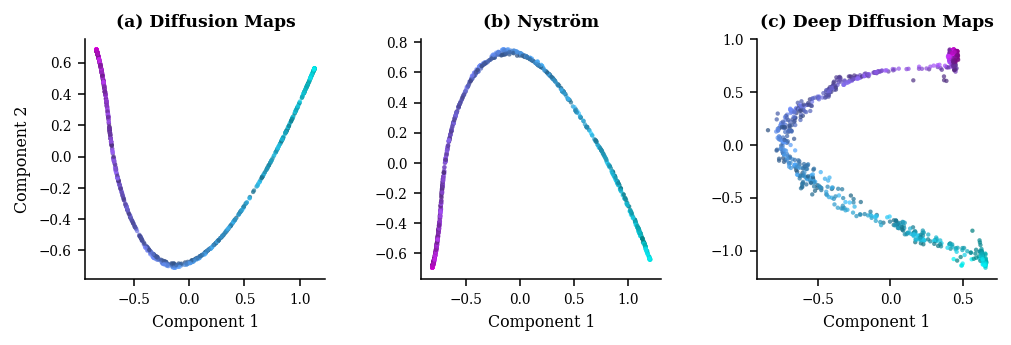

Saved: /content/pictures/deep_dm_swiss_roll.pdf


In [16]:
SWISS_RESULTS = run_paper_experiment('Swiss Roll', SWISS_DATA, SWISS_CONFIG, build_dense_encoder)
display(pd.DataFrame(result_rows('Swiss Roll', SWISS_RESULTS)).round(4))
plot_embedding_triplet(
    'Swiss Roll', SWISS_RESULTS[2], SWISS_DATA['test']['y'], 2,
    'deep_dm_swiss_roll.pdf'
)


## 5.9. MNIST

MNIST sử dụng 5.000 ảnh thuộc các chữ số từ 0 đến 5, với $q=5\times10^{-3}$, $\alpha=0$ và $t=1$. CNN được tối ưu trong 5.000 epoch. Hai cấu hình đầu ra được khảo sát: $d=2$ phục vụ trực quan hóa và $d=6$ đánh giá khả năng tái tạo biểu diễn khuếch tán ở số chiều lớn hơn.


Streaming output truncated to the last 5000 lines.
Epoch 2501/5000
8/8 - 0s - 36ms/step - loss: 1.7342e-10 - val_loss: 1.8879e-10
Epoch 2502/5000
8/8 - 0s - 38ms/step - loss: 1.7339e-10 - val_loss: 1.8877e-10
Epoch 2503/5000
8/8 - 0s - 42ms/step - loss: 1.7336e-10 - val_loss: 1.8874e-10
Epoch 2504/5000
8/8 - 0s - 41ms/step - loss: 1.7333e-10 - val_loss: 1.8871e-10
Epoch 2505/5000
8/8 - 0s - 36ms/step - loss: 1.7330e-10 - val_loss: 1.8869e-10
Epoch 2506/5000
8/8 - 0s - 37ms/step - loss: 1.7327e-10 - val_loss: 1.8866e-10
Epoch 2507/5000
8/8 - 0s - 37ms/step - loss: 1.7323e-10 - val_loss: 1.8863e-10
Epoch 2508/5000
8/8 - 0s - 36ms/step - loss: 1.7320e-10 - val_loss: 1.8861e-10
Epoch 2509/5000
8/8 - 0s - 37ms/step - loss: 1.7317e-10 - val_loss: 1.8858e-10
Epoch 2510/5000
8/8 - 0s - 38ms/step - loss: 1.7314e-10 - val_loss: 1.8855e-10
Epoch 2511/5000
8/8 - 0s - 36ms/step - loss: 1.7311e-10 - val_loss: 1.8853e-10
Epoch 2512/5000
8/8 - 0s - 41ms/step - loss: 1.7308e-10 - val_loss: 1.8850e-10
E

,Dataset,d,Subset,Method,MRE (%),CI lower (%),CI upper (%),MAE
0,MNIST,2,D_a,Nyström,4.3765,4.3657,4.3892,0.0141
1,MNIST,2,D_a,Deep Diffusion Maps,18.6747,18.6193,18.7293,0.0523
2,MNIST,2,D_b,Nyström,4.5913,4.5404,4.6538,0.0144
3,MNIST,2,D_b,Deep Diffusion Maps,23.0013,22.7937,23.2084,0.0649
4,MNIST,6,D_a,Nyström,0.9238,0.9232,0.9243,0.0071
5,MNIST,6,D_a,Deep Diffusion Maps,9.6349,9.6273,9.6424,0.0660
6,MNIST,6,D_b,Nyström,1.3218,1.3189,1.3247,0.0102
7,MNIST,6,D_b,Deep Diffusion Maps,10.5925,10.5607,10.6248,0.0738


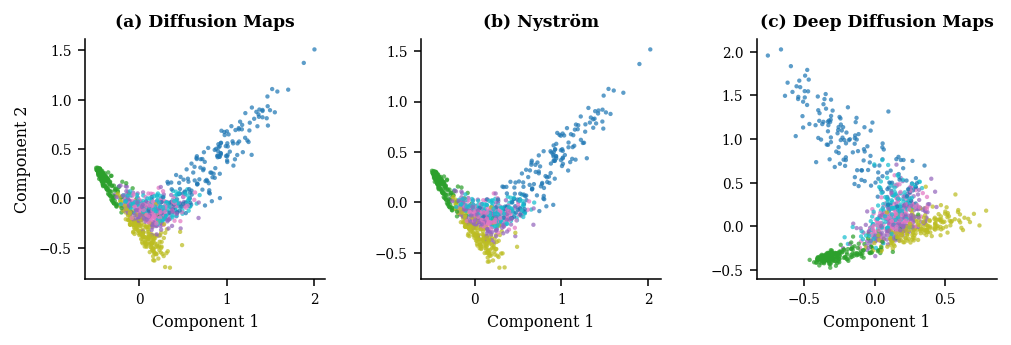

Saved: /content/pictures/deep_dm_mnist_d2.pdf


In [18]:
MNIST_RESULTS = run_paper_experiment('MNIST', MNIST_DATA, MNIST_CONFIG, build_mnist_encoder)
display(pd.DataFrame(result_rows('MNIST', MNIST_RESULTS)).round(4))
plot_embedding_triplet(
    'MNIST', MNIST_RESULTS[2], MNIST_DATA['test']['y'], 2,
    'deep_dm_mnist_d2.pdf'
)


## 5.10. Tổng hợp kết quả

Kết quả tổng hợp gồm MRE và khoảng tin cậy 95% của Nyström và DDM so với DM tham chiếu trên $D_a$ và $D_b$. Kết quả trên $D_a$ phản ánh mức độ khớp biểu diễn huấn luyện, còn kết quả trên $D_b$ phản ánh khả năng tổng quát hóa ngoài mẫu. Đường MRE theo decile cho biết sai số xuất hiện chủ yếu ở khoảng cách cục bộ hay toàn cục. MRE nhỏ hơn biểu thị mức độ tái tạo hình học khoảng cách của DM tốt hơn, nhưng không thay thế các tiêu chí độc lập về phân lớp, phân cụm hoặc bảo toàn lân cận.


,Dataset,d,Subset,Method,MRE (%),CI lower (%),CI upper (%),MAE
0,Swiss Roll,2,D_a,Nyström,10.8610,10.4908,11.2940,0.0394
1,Swiss Roll,2,D_a,Deep Diffusion Maps,30.6186,29.7519,31.6475,0.0868
2,Swiss Roll,2,D_b,Nyström,11.1088,10.7632,11.4655,0.0368
3,Swiss Roll,2,D_b,Deep Diffusion Maps,35.9558,35.1462,36.8213,0.0903
4,MNIST,2,D_a,Nyström,4.3765,4.3657,4.3892,0.0141
5,MNIST,2,D_a,Deep Diffusion Maps,18.6747,18.6193,18.7293,0.0523
6,MNIST,2,D_b,Nyström,4.5913,4.5404,4.6538,0.0144
7,MNIST,2,D_b,Deep Diffusion Maps,23.0013,22.7937,23.2084,0.0649
8,MNIST,6,D_a,Nyström,0.9238,0.9232,0.9243,0.0071
9,MNIST,6,D_a,Deep Diffusion Maps,9.6349,9.6273,9.6424,0.0660


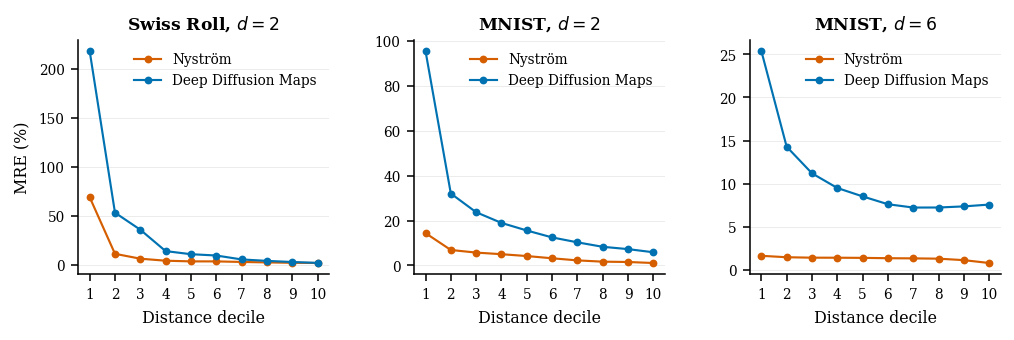

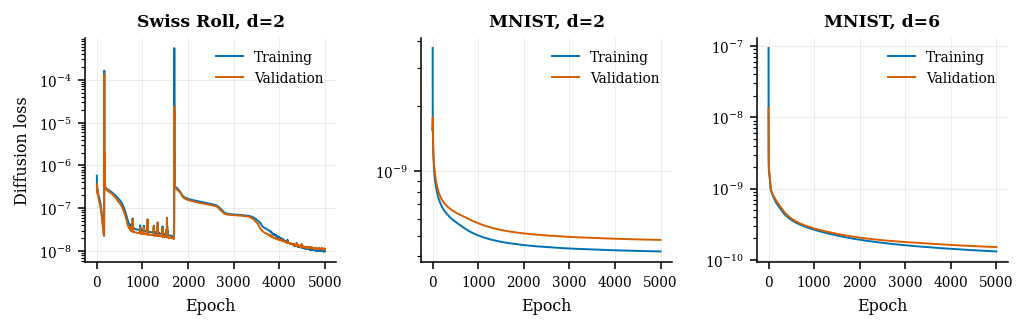

Saved: /content/pictures/deep_dm_mre_deciles.pdf
Saved: /content/pictures/deep_dm_training_history.pdf
Saved: /content/pictures/deep_dm_mre_summary.csv
Saved: /content/pictures/deep_dm_mre_by_decile.csv


In [19]:
SUMMARY = pd.DataFrame(result_rows('Swiss Roll', SWISS_RESULTS) + result_rows('MNIST', MNIST_RESULTS))
SUMMARY.to_csv(os.path.join(OUTPUT_DIR, 'deep_dm_mre_summary.csv'), index=False)
display(SUMMARY.round(4))

decile_records = []
for dataset_name, experiment_results in [('Swiss Roll', SWISS_RESULTS), ('MNIST', MNIST_RESULTS)]:
    for dimension, result in experiment_results.items():
        for method_key, method_label in [('nystrom', 'Nyström'), ('ddm', 'Deep Diffusion Maps')]:
            values = result[method_key]['metrics_test']['mre_by_decile']
            for decile, value in enumerate(values, start=1):
                decile_records.append({'Dataset': dataset_name, 'd': dimension, 'Method': method_label, 'Decile': decile, 'MRE (%)': 100.0 * value})

DECILES = pd.DataFrame(decile_records)
DECILES.to_csv(os.path.join(OUTPUT_DIR, 'deep_dm_mre_by_decile.csv'), index=False)

panels = [('Swiss Roll', 2), ('MNIST', 2), ('MNIST', 6)]
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.45))
method_colors = {'Nyström': '#D55E00', 'Deep Diffusion Maps': '#0072B2'}
for axis, (dataset_name, dimension) in zip(axes, panels):
    panel = DECILES[(DECILES['Dataset'] == dataset_name) & (DECILES['d'] == dimension)]
    for method in ['Nyström', 'Deep Diffusion Maps']:
        curve = panel[panel['Method'] == method]
        axis.plot(curve['Decile'], curve['MRE (%)'], marker='o', markersize=3, linewidth=1.1, color=method_colors[method], label=method)
    axis.set_title(f'{dataset_name}, $d={dimension}$', fontweight='bold')
    axis.set_xlabel('Distance decile')
    axis.set_ylabel('MRE (%)' if axis is axes[0] else '')
    axis.set_xticks(np.arange(1, 11))
    axis.grid(axis='y', linewidth=0.35, alpha=0.35)
    axis.legend(frameon=False)
fig.subplots_adjust(left=0.07, right=0.985, bottom=0.20, top=0.88, wspace=0.34)
figure_path = os.path.join(OUTPUT_DIR, 'deep_dm_mre_deciles.pdf')
fig.savefig(figure_path, bbox_inches='tight', pad_inches=0.04, facecolor='white')
plt.show()

history_entries = [('Swiss Roll, d=2', SWISS_RESULTS[2]['history']), ('MNIST, d=2', MNIST_RESULTS[2]['history']), ('MNIST, d=6', MNIST_RESULTS[6]['history'])]
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.35))
for axis, (label, history) in zip(axes, history_entries):
    axis.semilogy(history['loss'], color='#0072B2', linewidth=1.0, label='Training')
    axis.semilogy(history['val_loss'], color='#D55E00', linewidth=1.0, label='Validation')
    axis.set_title(label, fontweight='bold')
    axis.set_xlabel('Epoch')
    axis.set_ylabel('Diffusion loss' if axis is axes[0] else '')
    axis.grid(linewidth=0.35, alpha=0.35)
    axis.legend(frameon=False)
fig.subplots_adjust(left=0.07, right=0.985, bottom=0.20, top=0.88, wspace=0.34)
loss_path = os.path.join(OUTPUT_DIR, 'deep_dm_training_history.pdf')
fig.savefig(loss_path, bbox_inches='tight', pad_inches=0.04, facecolor='white')
plt.show()

print('Saved:', figure_path)
print('Saved:', loss_path)
print('Saved:', os.path.join(OUTPUT_DIR, 'deep_dm_mre_summary.csv'))
print('Saved:', os.path.join(OUTPUT_DIR, 'deep_dm_mre_by_decile.csv'))


## 5.11. Khả năng mở rộng và giới hạn

Sau huấn luyện, DDM ánh xạ mẫu mới bằng một lần truyền xuôi qua $f_\theta$; chi phí suy luận của mỗi mẫu do đó không tăng theo $|D_a|$ khi kiến trúc mạng được giữ cố định. Ngược lại, Nyström phải tính độ tương đồng giữa mẫu mới và toàn bộ $D_a$, nên chi phí suy luận vẫn phụ thuộc tuyến tính vào số mẫu huấn luyện.

DDM chưa loại bỏ nút thắt trong giai đoạn huấn luyện vì ma trận mục tiêu $T\in\mathbb{R}^{|D_a|\times|D_a|}$ vẫn được xây dựng tường minh. Bộ nhớ dành cho kernel và ma trận mục tiêu có độ phức tạp $O(|D_a|^2)$. Vì vậy, lợi ích chính nằm ở khả năng suy luận ngoài mẫu sau huấn luyện, không phải ở việc giảm hoàn toàn chi phí xây dựng toán tử khuếch tán ban đầu.
